In [1]:
import argparse
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
from torch.optim.lr_scheduler import StepLR
from copy import copy, deepcopy
import numpy as np

_ZERO_CLIP = 1e-7

In [2]:
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.l1 = nn.Linear(784, 64)
        self.l2 = nn.Linear(64, 10)

    def forward(self, x):
        x = x.reshape(-1, 28 * 28)
        x = self.l1(x)
        x = F.relu(x)
        x = self.l2(x)
        x = F.relu(x)
        output = F.log_softmax(x, dim=1)
        return output

In [3]:
# adapted from https://github.com/pytorch/examples/blob/main/mnist/main.py

batch_size=64
test_batch_size=1000
epochs=14
lr=1.0
gamma=0.7
seed=1337
log_interval=10
device=torch.device("cpu")

def train(model, train_loader, optimizer, epoch):
    model.train()
    for batch_idx, (data, target) in enumerate(train_loader):
        data, target = data.to(device), target.to(device)
        optimizer.zero_grad()
        output = model(data)
        loss = F.nll_loss(output, target)
        loss.backward()
        optimizer.step()
        if batch_idx % log_interval == 0:
            print('Train Epoch: {} [{}/{} ({:.0f}%)]\tLoss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), loss.item()))


def test(model, test_loader):
    model.eval()
    test_loss = 0
    correct = 0
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = model(data)
            test_loss += F.nll_loss(output, target, reduction='sum').item()  # sum up batch loss
            pred = output.argmax(dim=1, keepdim=True)  # get the index of the max log-probability
            correct += pred.eq(target.view_as(pred)).sum().item()

    test_loss /= len(test_loader.dataset)

    print('\nTest set: Average loss: {:.4f}, Accuracy: {}/{} ({:.0f}%)\n'.format(
        test_loss, correct, len(test_loader.dataset),
        100. * correct / len(test_loader.dataset)))


# Training settings
parser = argparse.ArgumentParser(description='PyTorch MNIST Example')

torch.manual_seed(seed)

train_kwargs = {'batch_size': batch_size}
test_kwargs = {'batch_size': test_batch_size}

transform=transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
    ])
train_dataset = datasets.MNIST('../data', train=True, download=True,
                   transform=transform)
test_dataset = datasets.MNIST('../data', train=False,
                   transform=transform)
train_loader = torch.utils.data.DataLoader(train_dataset,**train_kwargs)
test_loader = torch.utils.data.DataLoader(test_dataset, **test_kwargs)

model = Net().to(device)
optimizer = optim.Adadelta(model.parameters(), lr=lr)

scheduler = StepLR(optimizer, step_size=1, gamma=gamma)
for epoch in range(1, epochs + 1):
    train(model, train_loader, optimizer, epoch)
    test(model, test_loader)
    scheduler.step()

Train Epoch: 1 [0/60000 (0%)]	Loss: 2.278927
Train Epoch: 1 [640/60000 (1%)]	Loss: 1.523886
Train Epoch: 1 [1280/60000 (2%)]	Loss: 0.679461
Train Epoch: 1 [1920/60000 (3%)]	Loss: 0.429325
Train Epoch: 1 [2560/60000 (4%)]	Loss: 0.387348
Train Epoch: 1 [3200/60000 (5%)]	Loss: 0.334350
Train Epoch: 1 [3840/60000 (6%)]	Loss: 0.237787
Train Epoch: 1 [4480/60000 (7%)]	Loss: 0.351742
Train Epoch: 1 [5120/60000 (9%)]	Loss: 0.632779
Train Epoch: 1 [5760/60000 (10%)]	Loss: 0.197782
Train Epoch: 1 [6400/60000 (11%)]	Loss: 0.273693
Train Epoch: 1 [7040/60000 (12%)]	Loss: 0.356384
Train Epoch: 1 [7680/60000 (13%)]	Loss: 0.323842
Train Epoch: 1 [8320/60000 (14%)]	Loss: 0.172980
Train Epoch: 1 [8960/60000 (15%)]	Loss: 0.240228
Train Epoch: 1 [9600/60000 (16%)]	Loss: 0.159106
Train Epoch: 1 [10240/60000 (17%)]	Loss: 0.265598
Train Epoch: 1 [10880/60000 (18%)]	Loss: 0.166873
Train Epoch: 1 [11520/60000 (19%)]	Loss: 0.543257
Train Epoch: 1 [12160/60000 (20%)]	Loss: 0.307144
Train Epoch: 1 [12800/60000 (

In [4]:
from aihwkit.nn.conversion import convert_to_analog
from aihwkit.simulator.configs import InferenceRPUConfig

In [5]:
rpu_config = InferenceRPUConfig(drift_compensation = None)
rpu_config.mapping.max_input_size = 0
rpu_config.mapping.max_output_size = 0
rpu_config.forward.is_perfect = False

model.eval()
analog_model = convert_to_analog(
    model,
    rpu_config=rpu_config,
    exclude_modules=["l1"],
)
analog_model.eval()
print(analog_model)

AnalogWrapperNet(
  (l1): Linear(in_features=784, out_features=64, bias=True)
  (l2): AnalogLinear(
    in_features=64, out_features=10, bias=True, InferenceRPUConfig
    (analog_module): InferenceTile(RPUPulsed<float>[SimpleRPUDevice](10,64))
  )
)


In [6]:
analog_model = analog_model.to(device)

x, _ = next(iter(test_loader))
x = x.to(device)

with torch.no_grad():
    digital_output = model(x)
    analog_output = analog_model(x)

print("Maximum output difference:",
      (digital_output - analog_output).abs().max().item())
print("Prediction agreement:",
      (digital_output.argmax(1) == analog_output.argmax(1)).float().mean().item())

test(analog_model, test_loader)

Maximum output difference: 6.123563766479492
Prediction agreement: 0.9900000095367432

Test set: Average loss: 0.0952, Accuracy: 9745/10000 (97%)



In [7]:
g_min = 0  # units µS, default for AIHWKIT
g_max = 25 # units µS, default for AIHWKIT

scale = (g_max - g_min) / torch.max(torch.abs(model.l2.weight)).item()

def logical_to_differential(weight, scale):
    g_plus = g_min + scale * torch.max(weight, torch.zeros_like(weight))
    g_minus = g_min + scale * torch.max(-weight, torch.zeros_like(weight))

    return g_plus, g_minus

def differential_to_logical(g_plus, g_minus, scale):
    return (g_plus - g_minus) / scale

In [8]:
from aihwkit.inference.compensation.drift import GlobalDriftCompensation
from aihwkit.inference.compensation.base import BaseDriftCompensation
from aihwkit.simulator.tiles.functions import AnalogFunction

In [9]:
class DifferentiableGlobalDriftCompensation(BaseDriftCompensation):
    """Differentiable Global drift compensation.

    Uses a constant factor for compensating the drift.
    """

    def readout(self, out_tensor: Tensor) -> Tensor:
        """Read outs the mean abs."""
        return torch.clamp(torch.abs(out_tensor).mean(), min=0.0001)

    def get_readout_tensor(self, in_size: int) -> Tensor:
        """Return the read-out tensor.

        Uses the set of one-hot vectors (eye).
        """
        return torch.eye(in_size)

    def init_baseline(self, tile: "InferenceTileWithPeriphery") -> Tensor:
        """Initialize the base line for applying the compensation.

        Uses a all one tensor for read_out.

        Args:
            tile: forward output of the read out vector to compensate

        Returns:
            reference tensor readout
        """
        probe = self.get_readout_tensor(tile.in_size).to(tile.shared_weights)
        # We use this to work around the the @no_grad annotations
        # from tile._forward_drift_readout_tensor
        forward_output = AnalogFunction.apply(
            tile.get_analog_ctx(),
            tile,
            probe,
            tile.shared_weights,
            True,
        )
        
        ref_value = self.readout(forward_output)

        return ref_value

    def apply(self, forward_output: Tensor, ref_value: Tensor) -> Tensor:
        """Read out the current value from the output of the forward
        pass and returns the drift compensation alpha scale."""
        current_value = self.readout(forward_output)
        ratio = ref_value / current_value

        return ratio


    def __str__(self) -> str:
        return "{}()".format(self.__class__.__name__)

compensation = DifferentiableGlobalDriftCompensation()

In [10]:
from aihwkit.inference.noise.base import BaseNoiseModel
from aihwkit.inference.converter.base import BaseConductanceConverter
from aihwkit.inference.converter.conductance import SinglePairConductanceConverter

In [11]:
class DifferentiablePCMLikeNoiseModel(BaseNoiseModel):
    r"""Differentiable Noise model that was fitted and characterized on real PCM devices.

    Expected weight noise at assumed time of inference with expected
    programming noise at 0.

    The statistical noise model is based on measured PCM devices. See
    also `Nandakumar et al. ICECS (2019)`_

    Args:
        prog_coeff: Programming polynomial coeffs in
            :math:`\sum_i c_i \left(\frac{g_t}{g_\max}\right)^i`
        g_converter: instantiated class of the conductance converter
            (defaults to single pair)
        g_max: In :math:`\mu S`, the maximal conductance, ie the value
            the absolute max of the weights will be mapped to.
        t_read: Parameter of the 1/f fit (in seconds).
        t_0: Parameter of the drift fit (first reading time).

            Note:
                The ``t_inference`` is relative to this time `t0`
                e.g. t_inference counts from the completion of the programming
                of a device.
        prog_noise_scale: Scale for the programming noise.
        read_noise_scale: Scale for the read and accumulated noise.
        drift_scale: Scale for the  drift coefficient.
        prog_coeff_g_max_reference: reference :math:`g_\max` value
            when fitting the coefficients, since the result of the
            polynomial fit is given in uS. If
            ``prog_coeff_g_max_reference`` is not given and
            `prog_coeffs` are given explicitly, it will be set to
            ``g_max`` of the conductance converter.

    .. _`Nandakumar et al. ICECS (2019)`: https://ieeexplore.ieee.org/abstract/document/8964852

    """

    def __init__(
        self,
        prog_coeff: Optional[List[float]] = None,
        g_converter: Optional[BaseConductanceConverter] = None,
        g_max: Optional[float] = None,
        t_read: float = 250.0e-9,
        t_0: float = 20.0,
        prog_noise_scale: float = 1.0,
        read_noise_scale: float = 1.0,
        drift_scale: float = 1.0,
        prog_coeff_g_max_reference: Optional[float] = None,
    ):
        g_converter = deepcopy(g_converter) or SinglePairConductanceConverter(g_max=g_max)
        super().__init__(g_converter)

        self.g_max = getattr(self.g_converter, "g_max", g_max)
        if self.g_max is None:
            raise ValueError("g_max cannot be established from g_converter")

        if prog_coeff_g_max_reference is None:
            self.prog_coeff_g_max_reference = self.g_max
        else:
            self.prog_coeff_g_max_reference = prog_coeff_g_max_reference

        if prog_coeff is None:
            # standard g_max are defined in respect to 25.0 uS. Need to
            # adjust for that in case g_max is not equal to 25.0 uS
            self.prog_coeff = [0.26348, 1.9650, -1.1731]
            self.prog_coeff_g_max_reference = 25.0
        else:
            self.prog_coeff = prog_coeff

        self.t_0 = t_0
        self.t_read = t_read
        self.prog_noise_scale = prog_noise_scale
        self.read_noise_scale = read_noise_scale
        self.drift_scale = drift_scale

    def apply_programming_noise_to_conductance(self, g_target: Tensor, randn: Tensor) -> Tensor:
        """Apply programming noise to a target conductance Tensor.

        Programming noise with additive Gaussian noise with
        conductance dependency of the variance given by a 2-degree
        polynomial.
        """
        mat = 1
        sig_prog = self.prog_coeff[0]
        for coeff in self.prog_coeff[1:]:
            mat = mat * g_target / self.g_max
            sig_prog += mat * coeff

        sig_prog = sig_prog * self.g_max / self.prog_coeff_g_max_reference  # type: ignore
        g_prog = g_target + self.prog_noise_scale * sig_prog * randn
        g_prog.clamp_(min=0.0)  # no negative conductances allowed

        return g_prog

    def generate_drift_coefficients(self, g_target: Tensor, randn: Tensor) -> Tensor:
        """Return drift coefficients ``nu`` based on PCM measurements."""
        g_relative = torch.clamp(torch.abs(g_target / self.g_max), min=_ZERO_CLIP)

        # gt should be normalized wrt g_max
        mu_drift = (-0.0155 * torch.log(g_relative) + 0.0244).clamp(min=0.049, max=0.1)
        sig_drift = (-0.0125 * torch.log(g_relative) - 0.0059).clamp(min=0.008, max=0.045)
        nu_drift = torch.abs(mu_drift + sig_drift * randn).clamp(min=0.0)

        return nu_drift * self.drift_scale

    def apply_drift_noise_to_conductance(
        self, g_prog: Tensor, drift_noise_param: Tensor, t_inference: float, randn: Tensor
    ) -> Tensor:
        """Apply the noise and drift up to the assumed inference time
        point based on PCM measurements."""
        t = t_inference + self.t_0

        # drift
        if t > self.t_0:
            g_drift = g_prog * ((t / self.t_0) ** (-drift_noise_param))
        else:
            g_drift = g_prog

        # expected accumulated 1/f noise since start of programming at t=0
        if t > 0:
            relative = (g_prog.abs() / self.g_max).clamp(min = 1e-3 ** (1 / 0.65))
            q_s = (0.0088 / relative.pow(0.65)).clamp(
                max=0.2
            )
            sig_noise = q_s * np.sqrt(np.log((t + self.t_read) / (2 * self.t_read)))
            g_final = g_drift + torch.abs(g_drift) * self.read_noise_scale * sig_noise * randn
        else:
            g_final = g_prog

        return g_final.clamp(min=0.0)

noise = DifferentiablePCMLikeNoiseModel()

In [12]:
#tile = next(analog_model.l2.analog_tiles())

#weights = differential_to_logical(g_plus, g_minus, scale)

#print("Logical weights:", weights.shape)
#print("Shared weights:", tile.shared_weights.shape)

#probe = torch.eye(64, device=weights.device, dtype=weights.dtype)

#readout = AnalogFunction.apply(
#    tile.get_analog_ctx(),
#    tile,
#    probe,
#    weights.contiguous(),
#    True
#)

#grad_plus, grad_minus = torch.autograd.grad(
#    readout.square().sum(), (g_plus, g_minus)
#)

#print("Readout requires grad:", readout.requires_grad)
#print("Gradient norms:", grad_plus.norm().item(), grad_minus.norm().item())
#print("Finite gradients:",
#      torch.isfinite(grad_plus).all().item(),
#      torch.isfinite(grad_minus).all().item())

In [13]:
#del tile._parameters["shared_weights"]
#def use_conductances(gp, gm):
#    tile.shared_weights = differential_to_logical(
#        gp, gm, scale
#    ).contiguous()



In [14]:
class PCMSimulator(nn.Module):
    def __init__(self, model, templates, scales, noise, compensation):
        super().__init__()
        self.model = model
        self.model.requires_grad_(False)
        self.scales = tuple(scales)
        self.noise = noise
        self.compensation = compensation

        for i, layer in enumerate((self.model.l1, self.model.l2)):
            tile = next(layer.analog_tiles())
            if "shared_weights" in tile._parameters:
                del tile._parameters["shared_weights"]

            for name in ("program", "drift", "read"):
                for side in ("plus", "minus"):
                    self.register_buffer(
                        f"{name}_{side}_{i}",
                        torch.randn_like(templates[i]),
                    )

    def analog_forward(self, tile, inputs):
        return AnalogFunction.apply(
            tile.get_analog_ctx(), tile, inputs,
            tile.shared_weights, True,
        )

    def simulate_layer(self, i, layer, inputs, g_plus, g_minus, t):
        tile = next(layer.analog_tiles())

        def sample(name, side):
            return getattr(self, f"{name}_{side}_{i}")

        def install(gp, gm):
            tile.shared_weights = differential_to_logical(
                gp, gm, self.scales[i]
            ).contiguous()

        gp = self.noise.apply_programming_noise_to_conductance(
            g_plus, sample("program", "plus")
        )
        gm = self.noise.apply_programming_noise_to_conductance(
            g_minus, sample("program", "minus")
        )

        nu_plus = self.noise.generate_drift_coefficients(
            g_plus, sample("drift", "plus")
        )
        nu_minus = self.noise.generate_drift_coefficients(
            g_minus, sample("drift", "minus")
        )

        install(gp, gm)
        reference = self.compensation.init_baseline(tile)

        gp = self.noise.apply_drift_noise_to_conductance(
            gp, nu_plus, t, sample("read", "plus")
        )
        gm = self.noise.apply_drift_noise_to_conductance(
            gm, nu_minus, t, sample("read", "minus")
        )
        install(gp, gm)

        probe = self.compensation.get_readout_tensor(
            tile.in_size
        ).to(tile.shared_weights)
        alpha = self.compensation.apply(
            self.analog_forward(tile, probe), reference
        )

        return alpha * self.analog_forward(tile, inputs) + layer.bias

    def forward(self, x, g_plus, g_minus, t_inference):
        x = x.reshape(-1, 784)
        for i, layer in enumerate((self.model.l1, self.model.l2)):
            x = self.simulate_layer(
                i, layer, x, g_plus[i], g_minus[i], t_inference
            )
            x = F.relu(x)

        return F.log_softmax(x, dim=1)


class PCMEnsemble(nn.Module):
    def __init__(self, pairs, simulators, t_inferences):
        super().__init__()
        self.g_plus = nn.ParameterList([
            nn.Parameter(gp.detach().clone()) for gp, gm in pairs
        ])
        self.g_minus = nn.ParameterList([
            nn.Parameter(gm.detach().clone()) for gp, gm in pairs
        ])
        self.simulators = nn.ModuleList(simulators)
        self.t_inferences = tuple(t_inferences)

    def forward(self, x):
        return torch.stack([
            torch.stack([
                simulator(x, self.g_plus, self.g_minus, t)
                for t in self.t_inferences
            ])
            for simulator in self.simulators
        ])

In [15]:
from time import perf_counter

In [16]:
n_realizations = 4
t_inferences = [86400, 30 * 86400, 365 * 86400]  # 1 day, 30 days, 1 year
device = next(model.parameters()).device

weights = [model.l1.weight, model.l2.weight]
scales = [
    (g_max - g_min) / w.detach().abs().max().item()
    for w in weights
]

with torch.no_grad():
    pairs = [
        logical_to_differential(w, s)
        for w, s in zip(weights, scales)
    ]

simulators = [
    PCMSimulator(
        convert_to_analog(model, rpu_config=rpu_config).to(device),
        weights,
        scales,
        noise,
        compensation,
    )
    for _ in range(n_realizations)
]

ensemble = PCMEnsemble(pairs, simulators, t_inferences)
ensemble.eval()

optimizer = torch.optim.Adam(
    list(ensemble.g_plus) + list(ensemble.g_minus),
    lr=0.01,
)

def train_epoch(ensemble, train_loader, optimizer, epoch):
    ensemble.eval()  # Analog inference behavior; gradients remain enabled.

    total_loss = 0.0
    total_correct = 0
    total_predictions = 0

    for batch_idx, (x, target) in enumerate(train_loader):
        x = x.to(device)
        target = target.to(device)

        optimizer.zero_grad(set_to_none=True)

        # [realization, time, batch, class]
        outputs = ensemble(x)
        targets = target[None, None, :].expand(outputs.shape[:-1])

        loss = F.nll_loss(
            outputs.reshape(-1, outputs.shape[-1]),
            targets.reshape(-1),
        )

        loss.backward()
        optimizer.step()

        with torch.no_grad():
            for g in ensemble.g_plus:
                g.clamp_(g_min, g_max)
            for g in ensemble.g_minus:
                g.clamp_(g_min, g_max)

            count = targets.numel()
            total_loss += loss.item() * count
            total_correct += (
                outputs.argmax(dim=-1) == targets
            ).sum().item()
            total_predictions += count

        if batch_idx % log_interval == 0:
            print(
                f"Batch {batch_idx:4d}/{len(train_loader)}  "
                f"Loss: {total_loss / total_predictions:.4f}  "
                f"Accuracy: {100 * total_correct / total_predictions:.2f}%"
            )

    return (
        total_loss / total_predictions,
        total_correct / total_predictions,
    )

@torch.no_grad()
def evaluate(ensemble, test_loader):
    ensemble.eval()
    total_loss = 0.0
    total_correct = 0
    total_predictions = 0

    for x, target in test_loader:
        x, target = x.to(device), target.to(device)
        outputs = ensemble(x)
        targets = target[None, None, :].expand(outputs.shape[:-1])

        total_loss += F.nll_loss(
            outputs.reshape(-1, outputs.shape[-1]),
            targets.reshape(-1),
            reduction="sum",
        ).item()
        total_correct += (
            outputs.argmax(-1) == targets
        ).sum().item()
        total_predictions += targets.numel()

    return {
        "loss": total_loss / total_predictions,
        "accuracy": total_correct / total_predictions,
    }

history = []

for epoch in range(1, 2):
    start = perf_counter()
    loss, accuracy = train_epoch(ensemble, train_loader, optimizer, epoch)
    end = perf_counter()
    history.append({"loss": loss, "accuracy": accuracy})

    print(
        f"Epoch {epoch}: loss={loss:.4f}, "
        f"accuracy={100 * accuracy:.2f}%, "
        f"time taken {end - start}, "
        f"evaluation={evaluate(ensemble, test_loader)}%"
    )

Batch    0/938  Loss: 0.1207  Accuracy: 95.44%
Batch   10/938  Loss: 0.1494  Accuracy: 94.96%
Batch   20/938  Loss: 0.1711  Accuracy: 94.52%
Batch   30/938  Loss: 0.1559  Accuracy: 95.19%
Batch   40/938  Loss: 0.1395  Accuracy: 95.73%
Batch   50/938  Loss: 0.1349  Accuracy: 95.84%
Batch   60/938  Loss: 0.1304  Accuracy: 95.97%
Batch   70/938  Loss: 0.1289  Accuracy: 96.04%
Batch   80/938  Loss: 0.1292  Accuracy: 96.01%
Batch   90/938  Loss: 0.1282  Accuracy: 96.01%
Batch  100/938  Loss: 0.1266  Accuracy: 96.02%
Batch  110/938  Loss: 0.1282  Accuracy: 95.98%
Batch  120/938  Loss: 0.1277  Accuracy: 95.99%
Batch  130/938  Loss: 0.1278  Accuracy: 95.98%
Batch  140/938  Loss: 0.1307  Accuracy: 95.88%
Batch  150/938  Loss: 0.1301  Accuracy: 95.89%
Batch  160/938  Loss: 0.1302  Accuracy: 95.90%
Batch  170/938  Loss: 0.1266  Accuracy: 96.00%
Batch  180/938  Loss: 0.1252  Accuracy: 96.03%
Batch  190/938  Loss: 0.1262  Accuracy: 95.97%
Batch  200/938  Loss: 0.1275  Accuracy: 95.95%
Batch  210/93

In [25]:
from copy import deepcopy
from time import perf_counter

from aihwkit.inference import PCMLikeNoiseModel, GlobalDriftCompensation
from aihwkit.inference.converter.conductance import SinglePairConductanceConverter
from aihwkit.inference.converter.wpo import WeightProgrammingOptimizer

from copy import deepcopy
from time import perf_counter

import torch
import torch.nn.functional as F

from aihwkit.nn.conversion import convert_to_analog, convert_to_digital
from aihwkit.optim import AnalogSGD
from aihwkit.simulator.configs import WeightModifierType

# Start from the original digital checkpoint.
hwa_config = deepcopy(rpu_config)
hwa_config.forward.is_perfect = False

# Training-time weight perturbations.
hwa_config.modifier.type = WeightModifierType.ADD_NORMAL
hwa_config.modifier.std_dev = 0.1
hwa_config.modifier.rel_to_actual_wmax = True
hwa_config.modifier.pdrop = 0.0
hwa_config.modifier.enable_during_test = False

device = next(model.parameters()).device
hwa_model = convert_to_analog(
    deepcopy(model), rpu_config=hwa_config
).to(device)

hwa_model.requires_grad_(True)

# Freeze digital bias parameters, wherever the analog layer stores them.
for name, parameter in hwa_model.named_parameters():
    if name.split(".")[-1] == "bias":
        parameter.requires_grad_(False)

hwa_optimizer = AnalogSGD(hwa_model.parameters(), lr=0.01)
hwa_optimizer.regroup_param_groups(hwa_model)

hwa_history = []
start = perf_counter()

for epoch in range(1, 6):  # One epoch initially.
    hwa_model.train()
    loss_sum = correct = count = 0

    for batch_idx, (x, target) in enumerate(train_loader):
        x, target = x.to(device), target.to(device)

        hwa_optimizer.zero_grad(set_to_none=True)
        output = hwa_model(x)
        loss = F.nll_loss(output, target)
        loss.backward()
        hwa_optimizer.step()

        n = target.numel()
        loss_sum += loss.item() * n
        correct += (output.argmax(dim=1) == target).sum().item()
        count += n

        hwa_history.append({
            "epoch": epoch,
            "batch": batch_idx,
            "elapsed_s": perf_counter() - start,
            "batch_loss": loss.item(),
            "loss": loss_sum / count,
            "accuracy_pct": 100 * correct / count,
        })

        if batch_idx % 10 == 0:
            print(
                f"Batch {batch_idx:4d}/{len(train_loader)}  "
                f"Loss: {loss_sum / count:.4f}  "
                f"Accuracy: {100 * correct / count:.2f}%"
            )

# Export the trained logical weights before programming or drifting them.
hwa_model.eval()
hwa_reference = convert_to_digital(hwa_model).to(device).eval()

baseline_converter = SinglePairConductanceConverter(
    g_min=g_min, g_max=g_max
)

wpo_config = deepcopy(rpu_config)
wpo_config.noise_model = PCMLikeNoiseModel(
    g_converter=baseline_converter,
    t_0=noise.t_0,
    t_read=noise.t_read,
    prog_noise_scale=noise.prog_noise_scale,
    read_noise_scale=noise.read_noise_scale,
    drift_scale=noise.drift_scale,
)
wpo_config.drift_compensation = GlobalDriftCompensation()

weights = [hwa_reference.l1.weight, hwa_reference.l2.weight]

wpo = WeightProgrammingOptimizer(
    weights=weights_for_wpo,
    f_lst=[1.0],                      # One differential pair.
    rpu_config=wpo_config,
    t_steps=list(t_inferences),
    g_converter_baseline=baseline_converter,
    test_in_features=784,             # Representative calibration width.
    test_out_features=20,
    workers=1,                       # Start simply inside the notebook.
)

wpo.maxiter = 100
wpo.polish = False

start = perf_counter()
optimized_converter, success = wpo.run_optimizer()
print("WPO result:", success)
print("Elapsed seconds:", perf_counter() - start)
print("Baseline weight error:", wpo.loss_baseline)
print("Optimized weight error:", wpo.best_loss)

Batch    0/938  Loss: 0.0432  Accuracy: 98.44%
Batch   10/938  Loss: 0.3015  Accuracy: 91.34%
Batch   20/938  Loss: 0.3439  Accuracy: 90.25%
Batch   30/938  Loss: 0.3216  Accuracy: 90.98%
Batch   40/938  Loss: 0.2755  Accuracy: 92.04%
Batch   50/938  Loss: 0.2731  Accuracy: 91.97%
Batch   60/938  Loss: 0.2638  Accuracy: 92.21%
Batch   70/938  Loss: 0.2750  Accuracy: 92.23%
Batch   80/938  Loss: 0.2738  Accuracy: 92.15%
Batch   90/938  Loss: 0.2766  Accuracy: 92.20%
Batch  100/938  Loss: 0.2738  Accuracy: 92.30%
Batch  110/938  Loss: 0.2779  Accuracy: 92.15%
Batch  120/938  Loss: 0.2776  Accuracy: 92.19%
Batch  130/938  Loss: 0.2714  Accuracy: 92.29%
Batch  140/938  Loss: 0.2755  Accuracy: 92.27%
Batch  150/938  Loss: 0.2749  Accuracy: 92.32%
Batch  160/938  Loss: 0.2747  Accuracy: 92.40%
Batch  170/938  Loss: 0.2703  Accuracy: 92.54%
Batch  180/938  Loss: 0.2671  Accuracy: 92.57%
Batch  190/938  Loss: 0.2696  Accuracy: 92.55%
Batch  200/938  Loss: 0.2691  Accuracy: 92.55%
Batch  210/93

In [26]:
import time
import pandas as pd

def compare_models(
    digital_model,
    baseline_model,
    wpo_model,
    ensemble,
    loader,
    t_inferences,
    n_realizations=5,
    seed=12345,
):
    device = ensemble.g_plus[0].device
    times = tuple(t_inferences)
    records = []

    # One simulator is sufficient: resample its buffers for each realization.
    simulator = ensemble.simulators[0]
    noise_names = [
        f"{kind}_{side}_{i}"
        for i in range(len(ensemble.g_plus))
        for kind in ("program", "drift", "read")
        for side in ("plus", "minus")
    ]
    saved_noise = {
        name: getattr(simulator, name).clone()
        for name in noise_names
    }

    models = (digital_model, baseline_model, wpo_model, ensemble)
    saved_modes = [
        (module, module.training)
        for model_ in models
        for module in model_.modules()
    ]

    def synchronize():
        if device.type == "cuda":
            torch.cuda.synchronize(device)

    def measure(predict, method, realization, t):
        synchronize()
        start = time.perf_counter()
        loss_sum = 0.0
        correct = 0
        count = 0

        for x, target in loader:
            x = x.to(device)
            target = target.to(device)
            output = predict(x)

            # Works for both logits and normalized log-probabilities.
            loss_sum += F.cross_entropy(
                output, target, reduction="sum"
            ).item()
            correct += (output.argmax(-1) == target).sum().item()
            count += target.numel()

        synchronize()
        record = {
            "method": method,
            "realization": realization,
            "time_s": t,
            "loss": loss_sum / count,
            "accuracy_pct": 100 * correct / count,
            "evaluation_s": time.perf_counter() - start,
        }
        records.append(record)
        print(
            f"{method:9s}  realization={realization}  "
            f"t={t:g}s  loss={record['loss']:.4f}  "
            f"accuracy={record['accuracy_pct']:.3f}%"
        )

    cuda_devices = (
        [device.index if device.index is not None
         else torch.cuda.current_device()]
        if device.type == "cuda" else []
    )

    try:
        for model_ in models:
            model_.eval()

        with torch.random.fork_rng(devices=cuda_devices), torch.no_grad():
            measure(digital_model, "Digital", -1, 0)

            for realization in range(n_realizations):
                realization_seed = seed + 1000 * realization

                # Standard AIHWKit evaluation: program once, then drift
                # from that programmed state to each requested time.
                for label, model_ in (
                    ("Standard", baseline_model),
                    ("WPO", wpo_model),
                ):
                    torch.manual_seed(realization_seed)
                    model_.program_analog_weights()

                    for j, t in enumerate(times):
                        torch.manual_seed(realization_seed + j + 1)
                        model_.drift_analog_weights(t)
                        measure(model_, label, realization, t)

                # Fresh device samples, fixed across times and batches.
                torch.manual_seed(realization_seed)
                for name in noise_names:
                    getattr(simulator, name).normal_()

                for j, t in enumerate(times):
                    torch.manual_seed(realization_seed + j + 1)
                0.169366    measure(
                        lambda x, t=t: simulator(
                            x, ensemble.g_plus, ensemble.g_minus, t
                        ),
                        "Ours", realization, t,
                    )
    finally:
        with torch.no_grad():
            for name, value in saved_noise.items():
                getattr(simulator, name).copy_(value)

        for module, training in saved_modes:
            module.training = training

    raw = pd.DataFrame(records)
    summary = (
        raw.groupby(["method", "time_s"], sort=False)
        .agg(
            accuracy_mean_pct=("accuracy_pct", "mean"),
            accuracy_std_pp=("accuracy_pct", "std"),
            loss_mean=("loss", "mean"),
            evaluation_mean_s=("evaluation_s", "mean"),
        )
        .reset_index()
    )
    return raw, summary

In [27]:
baseline_config = deepcopy(wpo_config)
baseline_config.noise_model.g_converter = baseline_converter

baseline_model = convert_to_analog(
    model, rpu_config=baseline_config
).to(device).eval()

optimized_config = deepcopy(wpo_config)
optimized_config.noise_model.g_converter = optimized_converter

wpo_model = convert_to_analog(
    model, rpu_config=optimized_config
).to(device).eval()

comparison_raw, comparison_summary = compare_models(
    model,
    baseline_model,
    wpo_model,
    ensemble,
    test_loader,
    t_inferences,
    n_realizations=5,
)

display(comparison_summary)

Digital    realization=-1  t=0s  loss=0.0809  accuracy=97.830%
Standard   realization=0  t=86400s  loss=0.1406  accuracy=96.140%
Standard   realization=0  t=2.592e+06s  loss=0.1720  accuracy=95.460%
Standard   realization=0  t=3.1536e+07s  loss=0.2056  accuracy=94.860%
WPO        realization=0  t=86400s  loss=0.1351  accuracy=95.910%
WPO        realization=0  t=2.592e+06s  loss=0.1603  accuracy=95.590%
WPO        realization=0  t=3.1536e+07s  loss=0.1931  accuracy=94.920%
Ours       realization=0  t=86400s  loss=0.1270  accuracy=96.430%
Ours       realization=0  t=2.592e+06s  loss=0.1441  accuracy=95.810%
Ours       realization=0  t=3.1536e+07s  loss=0.1638  accuracy=94.950%
Standard   realization=1  t=86400s  loss=0.1588  accuracy=95.410%
Standard   realization=1  t=2.592e+06s  loss=0.1900  accuracy=94.630%
Standard   realization=1  t=3.1536e+07s  loss=0.2481  accuracy=93.500%
WPO        realization=1  t=86400s  loss=0.1614  accuracy=95.300%
WPO        realization=1  t=2.592e+06s  los

,method,time_s,accuracy_mean_pct,accuracy_std_pp,loss_mean,evaluation_mean_s
0,Digital,0,97.830,NaN,0.080932,0.752410
1,Standard,86400,96.020,0.395790,0.140033,0.799841
2,Standard,2592000,95.018,0.330333,0.179421,0.800615
3,Standard,31536000,94.286,0.494247,0.215392,0.812266
4,WPO,86400,95.872,0.335216,0.140148,0.835413
5,WPO,2592000,95.154,0.429453,0.170217,0.801784
6,WPO,31536000,94.052,0.748946,0.207716,0.798224
7,Ours,86400,96.182,0.182811,0.134230,1.192991
8,Ours,2592000,95.434,0.342826,0.152199,1.253193
9,Ours,31536000,94.720,0.317884,0.169366,1.207881


In [20]:
print("WPO baseline weight error:", wpo.loss_baseline)
print("WPO optimized weight error:", wpo.best_loss)

WPO baseline weight error: 0.13546102
WPO optimized weight error: 0.12391892778124025


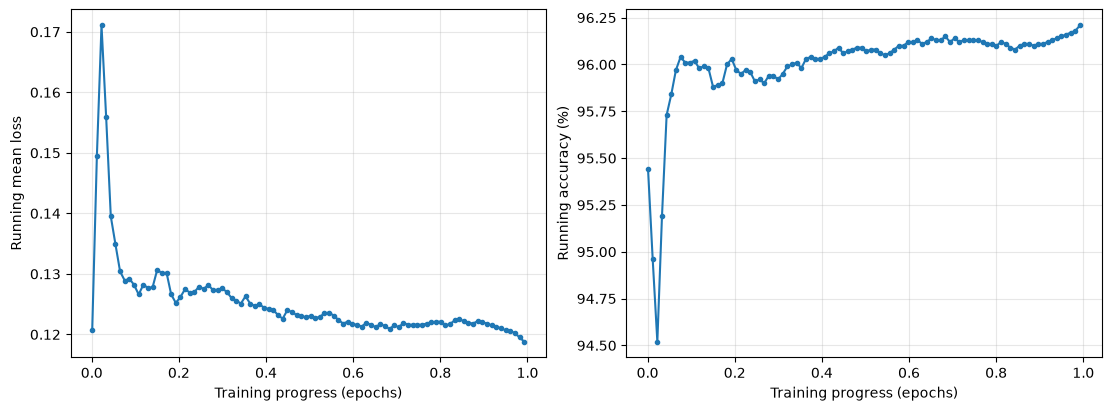

In [22]:
import re
import pandas as pd
import matplotlib.pyplot as plt

log_text = """
Batch    0/938  Loss: 0.1207  Accuracy: 95.44%
Batch   10/938  Loss: 0.1494  Accuracy: 94.96%
Batch   20/938  Loss: 0.1711  Accuracy: 94.52%
Batch   30/938  Loss: 0.1559  Accuracy: 95.19%
Batch   40/938  Loss: 0.1395  Accuracy: 95.73%
Batch   50/938  Loss: 0.1349  Accuracy: 95.84%
Batch   60/938  Loss: 0.1304  Accuracy: 95.97%
Batch   70/938  Loss: 0.1289  Accuracy: 96.04%
Batch   80/938  Loss: 0.1292  Accuracy: 96.01%
Batch   90/938  Loss: 0.1282  Accuracy: 96.01%
Batch  100/938  Loss: 0.1266  Accuracy: 96.02%
Batch  110/938  Loss: 0.1282  Accuracy: 95.98%
Batch  120/938  Loss: 0.1277  Accuracy: 95.99%
Batch  130/938  Loss: 0.1278  Accuracy: 95.98%
Batch  140/938  Loss: 0.1307  Accuracy: 95.88%
Batch  150/938  Loss: 0.1301  Accuracy: 95.89%
Batch  160/938  Loss: 0.1302  Accuracy: 95.90%
Batch  170/938  Loss: 0.1266  Accuracy: 96.00%
Batch  180/938  Loss: 0.1252  Accuracy: 96.03%
Batch  190/938  Loss: 0.1262  Accuracy: 95.97%
Batch  200/938  Loss: 0.1275  Accuracy: 95.95%
Batch  210/938  Loss: 0.1269  Accuracy: 95.97%
Batch  220/938  Loss: 0.1270  Accuracy: 95.96%
Batch  230/938  Loss: 0.1279  Accuracy: 95.91%
Batch  240/938  Loss: 0.1275  Accuracy: 95.92%
Batch  250/938  Loss: 0.1282  Accuracy: 95.90%
Batch  260/938  Loss: 0.1273  Accuracy: 95.94%
Batch  270/938  Loss: 0.1274  Accuracy: 95.94%
Batch  280/938  Loss: 0.1276  Accuracy: 95.92%
Batch  290/938  Loss: 0.1270  Accuracy: 95.95%
Batch  300/938  Loss: 0.1260  Accuracy: 95.99%
Batch  310/938  Loss: 0.1256  Accuracy: 96.00%
Batch  320/938  Loss: 0.1251  Accuracy: 96.01%
Batch  330/938  Loss: 0.1263  Accuracy: 95.98%
Batch  340/938  Loss: 0.1251  Accuracy: 96.03%
Batch  350/938  Loss: 0.1247  Accuracy: 96.04%
Batch  360/938  Loss: 0.1250  Accuracy: 96.03%
Batch  370/938  Loss: 0.1244  Accuracy: 96.03%
Batch  380/938  Loss: 0.1242  Accuracy: 96.04%
Batch  390/938  Loss: 0.1240  Accuracy: 96.06%
Batch  400/938  Loss: 0.1232  Accuracy: 96.07%
Batch  410/938  Loss: 0.1226  Accuracy: 96.09%
Batch  420/938  Loss: 0.1240  Accuracy: 96.06%
Batch  430/938  Loss: 0.1237  Accuracy: 96.07%
Batch  440/938  Loss: 0.1232  Accuracy: 96.08%
Batch  450/938  Loss: 0.1231  Accuracy: 96.09%
Batch  460/938  Loss: 0.1228  Accuracy: 96.09%
Batch  470/938  Loss: 0.1231  Accuracy: 96.07%
Batch  480/938  Loss: 0.1227  Accuracy: 96.08%
Batch  490/938  Loss: 0.1229  Accuracy: 96.08%
Batch  500/938  Loss: 0.1235  Accuracy: 96.06%
Batch  510/938  Loss: 0.1236  Accuracy: 96.05%
Batch  520/938  Loss: 0.1231  Accuracy: 96.06%
Batch  530/938  Loss: 0.1224  Accuracy: 96.08%
Batch  540/938  Loss: 0.1218  Accuracy: 96.10%
Batch  550/938  Loss: 0.1221  Accuracy: 96.10%
Batch  560/938  Loss: 0.1217  Accuracy: 96.12%
Batch  570/938  Loss: 0.1216  Accuracy: 96.12%
Batch  580/938  Loss: 0.1213  Accuracy: 96.13%
Batch  590/938  Loss: 0.1219  Accuracy: 96.11%
Batch  600/938  Loss: 0.1216  Accuracy: 96.12%
Batch  610/938  Loss: 0.1212  Accuracy: 96.14%
Batch  620/938  Loss: 0.1217  Accuracy: 96.13%
Batch  630/938  Loss: 0.1214  Accuracy: 96.13%
Batch  640/938  Loss: 0.1209  Accuracy: 96.15%
Batch  650/938  Loss: 0.1215  Accuracy: 96.12%
Batch  660/938  Loss: 0.1212  Accuracy: 96.14%
Batch  670/938  Loss: 0.1219  Accuracy: 96.12%
Batch  680/938  Loss: 0.1216  Accuracy: 96.13%
Batch  690/938  Loss: 0.1216  Accuracy: 96.13%
Batch  700/938  Loss: 0.1216  Accuracy: 96.13%
Batch  710/938  Loss: 0.1216  Accuracy: 96.13%
Batch  720/938  Loss: 0.1218  Accuracy: 96.12%
Batch  730/938  Loss: 0.1220  Accuracy: 96.11%
Batch  740/938  Loss: 0.1221  Accuracy: 96.11%
Batch  750/938  Loss: 0.1221  Accuracy: 96.10%
Batch  760/938  Loss: 0.1215  Accuracy: 96.12%
Batch  770/938  Loss: 0.1217  Accuracy: 96.11%
Batch  780/938  Loss: 0.1223  Accuracy: 96.09%
Batch  790/938  Loss: 0.1225  Accuracy: 96.08%
Batch  800/938  Loss: 0.1222  Accuracy: 96.10%
Batch  810/938  Loss: 0.1219  Accuracy: 96.11%
Batch  820/938  Loss: 0.1218  Accuracy: 96.11%
Batch  830/938  Loss: 0.1222  Accuracy: 96.10%
Batch  840/938  Loss: 0.1220  Accuracy: 96.11%
Batch  850/938  Loss: 0.1218  Accuracy: 96.11%
Batch  860/938  Loss: 0.1215  Accuracy: 96.12%
Batch  870/938  Loss: 0.1213  Accuracy: 96.13%
Batch  880/938  Loss: 0.1210  Accuracy: 96.14%
Batch  890/938  Loss: 0.1207  Accuracy: 96.15%
Batch  900/938  Loss: 0.1206  Accuracy: 96.16%
Batch  910/938  Loss: 0.1202  Accuracy: 96.17%
Batch  920/938  Loss: 0.1195  Accuracy: 96.18%
Batch  930/938  Loss: 0.1188  Accuracy: 96.21%"""

number = r"[-+]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][-+]?\d+)?"
pattern = re.compile(
    rf"Batch\s+(\d+)\s*/\s*(\d+)\s+"
    rf"Loss:\s*({number})\s+Accuracy:\s*({number})\s*%"
)

rows = [
    (int(batch), int(total), float(loss), float(accuracy))
    for batch, total, loss, accuracy in pattern.findall(log_text)
]

if not rows:
    raise ValueError("No matching batch log lines found.")

log_history = pd.DataFrame(
    rows, columns=["batch", "batches_per_epoch", "loss", "accuracy_pct"]
)

# Also handle multiple epochs pasted together: batch numbering resets.
log_history["epoch"] = (
    log_history["batch"].diff().lt(0).cumsum()
)
log_history["epoch_progress"] = (
    log_history["epoch"]
    + (log_history["batch"] + 1) / log_history["batches_per_epoch"]
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)

for ax, column, ylabel in (
    (axes[0], "loss", "Running mean loss"),
    (axes[1], "accuracy_pct", "Running accuracy (%)"),
):
    # Separate lines because cumulative metrics reset each epoch.
    for _, group in log_history.groupby("epoch", sort=False):
        ax.plot(group["epoch_progress"], group[column], marker=".")
    ax.set_xlabel("Training progress (epochs)")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)

plt.show()